<a href="https://colab.research.google.com/github/jhonathanrodriguez1/Curso---FDG2026/blob/main/Laboratorio_Calificado_N_%C2%B0_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PMD1 · Laboratorio Calificado N.° 03 — Caso 01: Delivery
**Fundamentos de Gestión de Datos · TECSUP · 2026-II · Docente: Pilar Rocío Sayán Mejía**

**Equipo N.°** 11 · **Sección** B. **Fecha:** 08/11/2026

| N.° | Apellidos y nombres | Código | Sección | Aporte principal | Aporte (%) |
|---|---|---|---|---|---|
| 1 |Rodriguez Gonzales Jhonathan Steven | | | | 100% |

| **Total**  **100 %** |

## Actividad 1 — Contexto, carga e integración

**Caso:** 01 Delivery: empresa de reparto a domicilio "Rapidito Delivery" con 5 sedes en Lima.

**Problema de negocio:** la empresa necesita estimar cuánto tardará una entrega para prometer tiempos realistas al cliente y organizar a sus repartidores. Queremos saber si la distancia del pedido explica el tiempo de entrega y qué tan confiable es esa relación una vez limpios los datos.

**Cada fila de Operaciones** representa una entrega: un pedido de un cliente, de un ítem del catálogo, despachado desde una sede en una fecha, con su distancia, ítems, carga operativa y tiempo de entrega en minutos.

In [23]:
# LECTURA: importamos pandas (tablas), sqlite3 (base de datos local), numpy (cálculos),
# matplotlib (gráficos) y scikit-learn (regresión y métricas). Todo viene instalado en Colab.
# RESULTADO: esta celda no muestra salida; solo deja listas las herramientas.
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [24]:
# LECTURA: cargamos el libro de Excel del caso Delivery directamente desde la ruta RAW del
# repositorio de GitHub (evidencia de carga desde GitHub). sheet_name=None trae todas las hojas.
# INTERPRETACIÓN: el libro trae LEEME (instrucciones) y las 4 tablas del caso.
# RESULTADO: Operaciones tiene 466 entregas y 9 columnas; Clientes 120, Catalogo 20 y Sedes 5 filas.
URL = "https://raw.githubusercontent.com/Rociosayan/PMD1_Fundamentos_Gestion_Datos/main/casos_PMD1/01_Delivery/01_Delivery_PMD1.xlsx"
hojas = pd.read_excel(URL, sheet_name=None)
for nombre, tabla in hojas.items():
    print(f"{nombre}: {tabla.shape[0]} filas x {tabla.shape[1]} columnas")

LEEME: 16 filas x 2 columnas
Operaciones: 466 filas x 9 columnas
Clientes: 120 filas x 4 columnas
Catalogo: 20 filas x 4 columnas
Sedes: 5 filas x 3 columnas


In [25]:
# LECTURA: guardamos cada hoja (menos LEEME) como tabla en una base SQLite llamada delivery.db.
# Usamos if_exists="replace" para que el notebook se pueda volver a ejecutar sin errores.
# INTERPRETACIÓN: desde aquí trabajamos con SQL sobre las 4 tablas, como pide el laboratorio.
# RESULTADO: la consulta a sqlite_master confirma que existen las 4 tablas en la base.
conn = sqlite3.connect("delivery.db")
for nombre in ["Operaciones", "Clientes", "Catalogo", "Sedes"]:
    hojas[nombre].to_sql(nombre.lower(), conn, if_exists="replace", index=False)
pd.read_sql("SELECT name AS tabla FROM sqlite_master WHERE type='table'", conn)

,tabla
0,tabla_analitica
1,dataset_limpio
2,predicciones_regresion
3,operaciones
4,clientes
5,catalogo
6,sedes


In [26]:
# LECTURA: con SQL contamos las filas de cada tabla y cuántos valores distintos tiene su clave primaria.
# Si filas == claves_distintas, la clave es única.
# INTERPRETACIÓN: Clientes, Catalogo y Sedes tienen claves únicas. En Operaciones hay 466 filas pero
# solo 460 id_operacion distintos: 6 entregas están repetidas (las tratamos en la limpieza).
consultas = {
    "operaciones": "id_operacion",
    "clientes": "id_cliente",
    "catalogo": "id_catalogo",
    "sedes": "id_sede",
}
verif = []
for tabla, clave in consultas.items():
    r = pd.read_sql(f"SELECT COUNT(*) AS filas, COUNT(DISTINCT {clave}) AS claves_distintas FROM {tabla}", conn)
    verif.append({"tabla": tabla, "clave": clave, "filas": r.filas[0], "claves_distintas": r.claves_distintas[0]})
verificacion_claves = pd.DataFrame(verif)
verificacion_claves["clave_unica"] = verificacion_claves.filas == verificacion_claves.claves_distintas
verificacion_claves

,tabla,clave,filas,claves_distintas,clave_unica
0,operaciones,id_operacion,466,460,False
1,clientes,id_cliente,120,120,True
2,catalogo,id_catalogo,20,20,True
3,sedes,id_sede,5,5,True


In [27]:
# LECTURA: buscamos claves huérfanas: entregas cuyo cliente, ítem o sede no existe en su tabla.
# Usamos LEFT JOIN y contamos las filas donde la tabla relacionada quedó vacía (IS NULL).
# INTERPRETACIÓN/RESULTADO: 0 huérfanas en las tres relaciones; todas las entregas se pueden
# asociar a un cliente, un ítem y una sede, así que la integración no tendrá vacíos por claves.
huerfanas = {}
for tabla, clave in [("clientes", "id_cliente"), ("catalogo", "id_catalogo"), ("sedes", "id_sede")]:
    q = f'''SELECT COUNT(*) AS n FROM operaciones o
            LEFT JOIN {tabla} t ON o.{clave} = t.{clave}
            WHERE t.{clave} IS NULL'''
    huerfanas[clave] = int(pd.read_sql(q, conn).n[0])
huerfanas

{'id_cliente': 0, 'id_catalogo': 0, 'id_sede': 0}

In [28]:
# LECTURA: construimos la tabla analítica uniendo Operaciones con Clientes, Catalogo y Sedes con LEFT JOIN.
# Partimos de Operaciones porque es la tabla de hechos: LEFT JOIN conserva TODAS las entregas aunque
# alguna no encontrara su cliente/ítem/sede. Elegimos columnas para no repetir las claves.
# RESULTADO: 466 filas (las mismas de Operaciones, no se perdió ninguna entrega) y 17 columnas.
q = '''
CREATE TABLE tabla_analitica AS
SELECT o.*, c.nombre_cliente, c.ciudad, c.antiguedad_meses,
       p.nombre_item, p.nivel, p.precio_referencia_soles,
       s.nombre_sede, s.zona
FROM operaciones o
LEFT JOIN clientes c ON o.id_cliente  = c.id_cliente
LEFT JOIN catalogo p ON o.id_catalogo = p.id_catalogo
LEFT JOIN sedes s    ON o.id_sede     = s.id_sede
'''
conn.execute("DROP TABLE IF EXISTS tabla_analitica")
conn.execute(q)
df = pd.read_sql("SELECT * FROM tabla_analitica", conn)
df_original = df.copy()   # copia de seguridad: los datos originales no se modifican
print("Tabla analítica:", df.shape[0], "filas x", df.shape[1], "columnas")

Tabla analítica: 466 filas x 17 columnas


**Pregunta 1.** Cada fila de la tabla principal representa **una entrega** de Rapidito Delivery. La tabla analítica tiene **466 filas y 17 columnas**. Elegimos **LEFT JOIN** desde Operaciones porque es la tabla de hechos y no queremos perder ninguna entrega: si alguna no encontrara su cliente, ítem o sede, igual se conservaría con esos campos vacíos. En nuestro caso no hubo claves huérfanas, por eso las 466 entregas quedaron completas.

## Actividad 2 — Exploración de los datos (EDA)

In [29]:
# LECTURA: mostramos las 5 primeras filas para ver cómo quedó la tabla integrada.
# INTERPRETACIÓN: cada entrega ya tiene datos del cliente (ciudad), del ítem (nivel, precio) y de la sede (zona).
# Se nota que la fecha viene como texto y que conviven formatos (AAAA-MM-DD y D/M/AAAA).
df.head()

,id_operacion,id_cliente,id_catalogo,id_sede,fecha,distancia_km,items_pedido,carga_operativa_pct,tiempo_entrega_min,nombre_cliente,ciudad,antiguedad_meses,nombre_item,nivel,precio_referencia_soles,nombre_sede,zona
0,O010001,C01002,P01008,S013,2025-02-05,5.89,4.0,39.3,26.74,Gabriela Chávez Torres,Cusco,9,Ensalada de quinua,intermedio,21.58,Rapidito Delivery San Miguel,Oeste
1,O010002,C01067,P01002,S011,2025-07-20,5.66,3.0,30.5,34.39,Martín Benites Gómez,Lima,4,Pollo a la brasa 1/4,intermedio,35.22,Rapidito Delivery Los Olivos,Norte
2,O010003,C01109,P01013,S015,2025-05-25,2.41,1.0,14.6,18.92,Carlos Ramírez Castillo,Trujillo,1,Ensalada Waldorf,basico,21.38,Rapidito Delivery Surco,Sur
3,O010004,C01086,P01010,S012,2025-09-14,5.99,4.0,33.9,31.02,Diego Condori Gutiérrez,Huancayo,4,Pizza pepperoni familiar,especial,47.51,Rapidito Delivery Cercado de Lima,Centro
4,O010005,C01071,P01020,S011,2025-09-11,9.41,7.0,58.4,66.40,Andrés Reyes Paredes,Huancayo,1,Ensalada fresca de la casa,intermedio,21.74,Rapidito Delivery Los Olivos,Norte


In [30]:
# LECTURA: info() muestra el tipo de dato y cuántos valores no nulos tiene cada columna.
# INTERPRETACIÓN: fecha es texto (no fecha), las variables numéricas son float. Hay columnas con menos de
# 466 no nulos: distancia_km (462), items_pedido (461) y tiempo_entrega_min (463) tienen faltantes.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 466 entries, 0 to 465
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_operacion             466 non-null    object 
 1   id_cliente               466 non-null    object 
 2   id_catalogo              466 non-null    object 
 3   id_sede                  466 non-null    object 
 4   fecha                    466 non-null    object 
 5   distancia_km             462 non-null    float64
 6   items_pedido             461 non-null    float64
 7   carga_operativa_pct      466 non-null    float64
 8   tiempo_entrega_min       463 non-null    float64
 9   nombre_cliente           466 non-null    object 
 10  ciudad                   466 non-null    object 
 11  antiguedad_meses         466 non-null    int64  
 12  nombre_item              466 non-null    object 
 13  nivel                    466 non-null    object 
 14  precio_referencia_soles  4

In [31]:
# LECTURA: describe() resume las columnas numéricas (media, desviación, mínimo, cuartiles y máximo).
# INTERPRETACIÓN: la distancia va de 1.11 a 11.89 km (media 5.58). El tiempo de entrega va de 12.68 a 90.88 min
# con media 29.13 y mediana 25.48: la media es mayor que la mediana porque hay entregas muy lentas (cola a la derecha).
df.describe().round(2)

,distancia_km,items_pedido,carga_operativa_pct,tiempo_entrega_min,antiguedad_meses,precio_referencia_soles
count,462.00,461.00,466.00,463.00,466.00,466.00
mean,5.58,3.17,33.71,29.13,6.67,36.90
std,3.11,1.83,21.33,13.38,3.45,10.52
min,1.11,1.00,1.00,12.68,1.00,21.31
25%,2.57,1.00,15.05,18.76,4.00,32.46
50%,5.42,3.00,33.50,25.48,7.00,35.22
75%,8.66,5.00,49.50,36.23,9.00,47.51
max,11.89,9.00,90.10,90.88,12.00,50.39


In [32]:
# LECTURA: value_counts() cuenta cuántas entregas hay por zona, nivel del ítem y ciudad del cliente.
# INTERPRETACIÓN: muestra la composición de la base y si hay categorías escritas de forma distinta.
for col in ["zona", "nivel", "ciudad"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False), "\n")

--- zona ---
zona
Norte     181
Sur       102
Centro     97
Oeste      86
Name: count, dtype: int64 

--- nivel ---
nivel
basico        192
intermedio    169
especial      105
Name: count, dtype: int64 

--- ciudad ---
ciudad
Arequipa    98
Cusco       87
Huancayo    78
Lima        71
Piura       68
Trujillo    64
Name: count, dtype: int64 



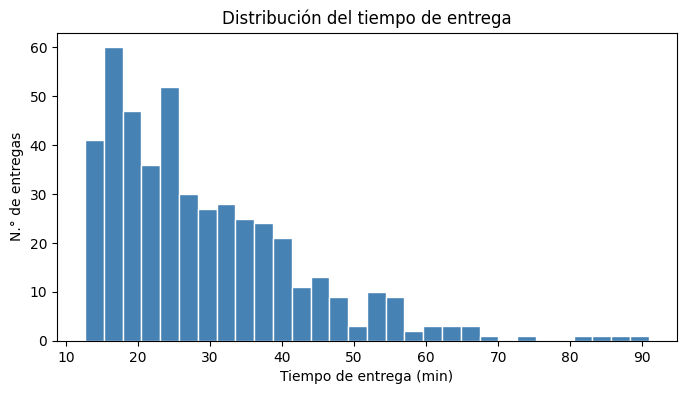

In [33]:
# GRÁFICO 1 — LECTURA: histograma del tiempo de entrega (variable objetivo).
# INTERPRETACIÓN: la mayoría de entregas tarda entre 15 y 40 minutos, pero la distribución tiene cola a la
# derecha con unas pocas entregas de más de 70 minutos que podrían ser valores extremos.
plt.figure(figsize=(8, 4))
plt.hist(df["tiempo_entrega_min"].dropna(), bins=30, color="steelblue", edgecolor="white")
plt.title("Distribución del tiempo de entrega")
plt.xlabel("Tiempo de entrega (min)"); plt.ylabel("N.° de entregas")
plt.show()

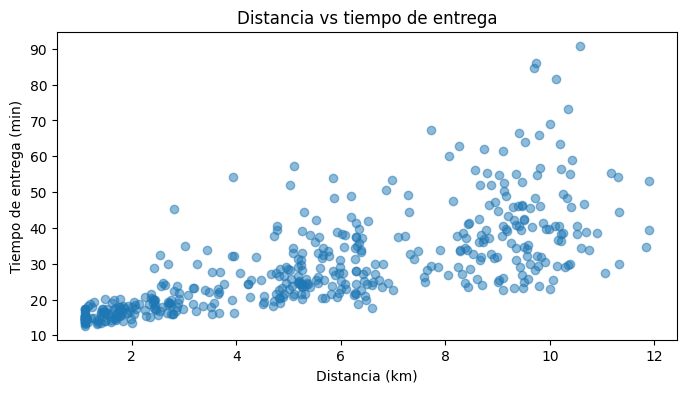

Correlación distancia-tiempo (datos sin limpiar): 0.7242


In [34]:
# GRÁFICO 2 — LECTURA: dispersión distancia (predictora) vs tiempo de entrega (objetivo).
# INTERPRETACIÓN: a mayor distancia, mayor tiempo; la nube sube de izquierda a derecha (relación positiva).
# Hay puntos muy altos que se alejan de la tendencia (posibles atípicos).
plt.figure(figsize=(8, 4))
plt.scatter(df["distancia_km"], df["tiempo_entrega_min"], alpha=0.5)
plt.title("Distancia vs tiempo de entrega")
plt.xlabel("Distancia (km)"); plt.ylabel("Tiempo de entrega (min)")
plt.show()
print("Correlación distancia-tiempo (datos sin limpiar):", round(df["distancia_km"].corr(df["tiempo_entrega_min"]), 4))

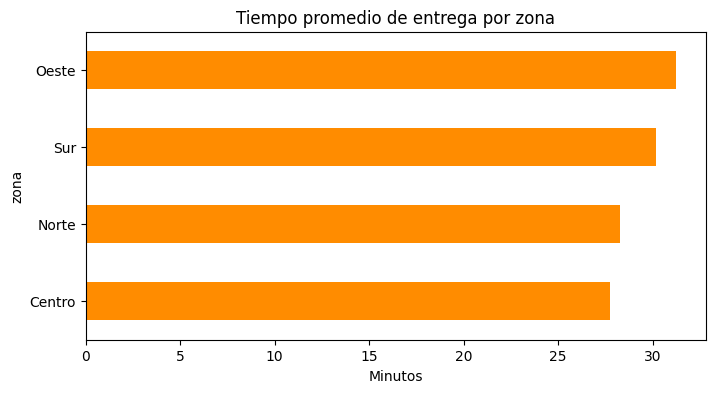

,tiempo_entrega_min
zona,
Centro,27.73
Norte,28.28
Sur,30.19
Oeste,31.25


In [35]:
# GRÁFICO 3 — LECTURA: tiempo promedio de entrega por zona de la sede.
# INTERPRETACIÓN: permite comparar si alguna zona entrega más lento que otras; sirve para ubicar
# dónde reforzar repartidores.
prom_zona = df.groupby("zona")["tiempo_entrega_min"].mean().sort_values()
prom_zona.plot(kind="barh", figsize=(8, 4), color="darkorange")
plt.title("Tiempo promedio de entrega por zona")
plt.xlabel("Minutos")
plt.show()
prom_zona.round(2)

**Pregunta 2.** `info()` muestra 466 filas y 17 columnas: los identificadores y textos son de tipo texto y la **fecha también viene como texto**, por lo que hay que convertirla. Hay faltantes en `distancia_km` (4), `items_pedido` (5) y `tiempo_entrega_min` (3). `describe()` indica que la distancia va de 1.11 a 11.89 km (media 5.58 km) y el tiempo de entrega de 12.68 a 90.88 min (media 29.13 y mediana 25.48), lo que anticipa entregas muy lentas. `value_counts()` muestra que la zona Norte concentra más entregas (181, porque tiene 2 sedes), seguida de Sur (102), Centro (97) y Oeste (86); en el catálogo predominan ítems de nivel básico (192). Las categorías de zona, nivel y ciudad no tienen variantes de escritura.

**Pregunta 3.** El **histograma** muestra que la mayoría de entregas tarda entre 15 y 40 minutos, con una cola a la derecha de entregas que superan los 60 minutos. La **dispersión** muestra una relación positiva clara: a más kilómetros, más minutos (correlación 0.7242 sin limpiar), aunque hay puntos muy altos que se salen de la tendencia. Las **barras por zona** muestran diferencias moderadas: Centro es la más rápida (27.73 min) y Oeste la más lenta (31.25 min). Antes de limpiar ya se perciben fechas en dos formatos, nulos en las variables del modelo, IDs de operación repetidos y valores extremos del tiempo.

## Actividad 3 — Diagnóstico y limpieza

In [36]:
# LECTURA: antes de cambiar nada, cuantificamos cada problema de calidad. Revisamos:
# nulos por columna, duplicados exactos, fechas que no siguen AAAA-MM-DD, textos con espacios sobrantes,
# claves huérfanas y valores extremos del tiempo con la regla IQR (fuera de Q1-1.5*IQR o Q3+1.5*IQR).
# RESULTADO: la tabla de diagnóstico resume problema, columna afectada y cantidad.
diag = []
for col in df.columns:
    n = int(df[col].isna().sum())
    if n > 0:
        diag.append({"problema": "Valores nulos", "columna": col, "cantidad": n})

diag.append({"problema": "Filas duplicadas exactas", "columna": "todas", "cantidad": int(df.duplicated().sum())})

fecha_txt = df["fecha"].astype(str)
fechas_otro_formato = int((~fecha_txt.str.match(r"^\d{4}-\d{2}-\d{2}$")).sum())
diag.append({"problema": "Fecha en formato distinto (D/M/AAAA)", "columna": "fecha", "cantidad": fechas_otro_formato})

for col in ["nombre_cliente", "ciudad", "nombre_item", "nivel", "nombre_sede", "zona"]:
    txt = df[col].astype(str)
    n = int((txt != txt.str.strip()).sum())
    if n > 0:
        diag.append({"problema": "Texto con espacios sobrantes", "columna": col, "cantidad": n})

diag.append({"problema": "Claves huérfanas", "columna": "id_cliente/id_catalogo/id_sede", "cantidad": sum(huerfanas.values())})

q1, q3 = df["tiempo_entrega_min"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = int(((df["tiempo_entrega_min"] < lim_inf) | (df["tiempo_entrega_min"] > lim_sup)).sum())
diag.append({"problema": f"Valores extremos IQR (>{lim_sup:.2f} min)", "columna": "tiempo_entrega_min", "cantidad": n_out})

diagnostico = pd.DataFrame(diag)
diagnostico

,problema,columna,cantidad
0,Valores nulos,distancia_km,4
1,Valores nulos,items_pedido,5
2,Valores nulos,tiempo_entrega_min,3
3,Filas duplicadas exactas,todas,6
4,Fecha en formato distinto (D/M/AAAA),fecha,20
5,Texto con espacios sobrantes,nombre_cliente,22
6,Claves huérfanas,id_cliente/id_catalogo/id_sede,0
7,Valores extremos IQR (>62.44 min),tiempo_entrega_min,12


In [37]:
# LECTURA: aplicamos la limpieza sobre una COPIA (df_limpio); df_original queda intacto.
# Cada paso se registra en la bitácora con el motivo y las filas que quedan.
df_limpio = df_original.copy()
bitacora = []
def registrar(paso, motivo):
    bitacora.append({"paso": paso, "motivo": motivo, "filas_que_quedan": len(df_limpio)})

registrar("0. Copia de los datos originales", "Conservar df_original sin cambios")

# 1) Duplicados exactos: la misma entrega cargada dos veces infla conteos y pesa doble en el modelo
df_limpio = df_limpio.drop_duplicates()
registrar("1. Eliminar duplicados exactos", "Una entrega repetida se contaría dos veces")

# 2) Textos: quitamos espacios al inicio/fin para que el mismo nombre no aparezca como dos valores
for col in ["nombre_cliente", "ciudad", "nombre_item", "nivel", "nombre_sede", "zona"]:
    df_limpio[col] = df_limpio[col].str.strip()
registrar("2. Quitar espacios en textos", "Evitar nombres iguales tratados como distintos")

# 3) Fechas: convertimos ambos formatos (AAAA-MM-DD y D/M/AAAA) a un solo tipo fecha
iso = pd.to_datetime(df_limpio["fecha"], format="%Y-%m-%d", errors="coerce")
dmy = pd.to_datetime(df_limpio["fecha"], format="%d/%m/%Y", errors="coerce")
df_limpio["fecha"] = iso.fillna(dmy)
registrar("3. Unificar formato de fecha", "Una sola fecha válida para análisis por mes")

# 4) Nulos en objetivo o predictora: sin tiempo o sin distancia no se puede entrenar ni evaluar la regresión.
#    Son pocas filas, así que eliminarlas no sesga la base (inventarlas sí podría distorsionar la relación).
df_limpio = df_limpio.dropna(subset=["tiempo_entrega_min", "distancia_km"])
registrar("4. Eliminar nulos en tiempo y distancia", "Son las variables del modelo; imputarlas inventaría la relación")

# 5) Nulos en items_pedido (otra columna): imputamos con la mediana, que no se deja arrastrar por extremos
#    y conserva la entrega para el análisis.
mediana_items = df_limpio["items_pedido"].median()
df_limpio["items_pedido"] = df_limpio["items_pedido"].fillna(mediana_items)
registrar(f"5. Imputar items_pedido con la mediana ({mediana_items:.0f})", "Columna secundaria; se conserva la fila")

# 6) Valores extremos del tiempo (regla IQR): entregas muy lentas fuera de lo habitual (incidencias)
#    que jalan la recta hacia arriba.
df_limpio = df_limpio[(df_limpio["tiempo_entrega_min"] >= lim_inf) & (df_limpio["tiempo_entrega_min"] <= lim_sup)]
registrar("6. Retirar extremos IQR del tiempo", f"Tiempos > {lim_sup:.2f} min no representan una entrega típica")

bitacora = pd.DataFrame(bitacora)
bitacora

,paso,motivo,filas_que_quedan
0,0. Copia de los datos originales,Conservar df_original sin cambios,466
1,1. Eliminar duplicados exactos,Una entrega repetida se contaría dos veces,460
2,2. Quitar espacios en textos,Evitar nombres iguales tratados como distintos,460
3,3. Unificar formato de fecha,Una sola fecha válida para análisis por mes,460
4,4. Eliminar nulos en tiempo y distancia,Son las variables del modelo; imputarlas inven...,453
5,5. Imputar items_pedido con la mediana (3),Columna secundaria; se conserva la fila,453
6,6. Retirar extremos IQR del tiempo,Tiempos > 62.44 min no representan una entrega...,441


In [38]:
# LECTURA: comparamos la base antes y después de limpiar: filas, nulos, duplicados, promedio del
# objetivo y correlación entre distancia y tiempo.
# INTERPRETACIÓN: muestra cuánto se depuró la base y si la relación predictora-objetivo se volvió más clara.
def resumen(d):
    return {
        "filas": len(d),
        "nulos_totales": int(d.isna().sum().sum()),
        "duplicados": int(d.duplicated().sum()),
        "promedio_tiempo_min": round(d["tiempo_entrega_min"].mean(), 2),
        "correlacion_distancia_tiempo": round(d["distancia_km"].corr(d["tiempo_entrega_min"]), 4),
    }
comparacion = pd.DataFrame({"antes": resumen(df_original), "despues": resumen(df_limpio)})
comparacion

,antes,despues
filas,466.0000,441.0000
nulos_totales,12.0000,0.0000
duplicados,6.0000,0.0000
promedio_tiempo_min,29.1300,28.0700
correlacion_distancia_tiempo,0.7242,0.7433


In [39]:
# LECTURA: guardamos la base limpia en SQLite como dataset_limpio. La fecha se guarda como texto AAAA-MM-DD.
# Luego la comprobamos con una consulta SQL.
# RESULTADO: la consulta debe devolver las mismas filas, promedio de tiempo y distancia que df_limpio.
guardar = df_limpio.copy()
guardar["fecha"] = guardar["fecha"].dt.strftime("%Y-%m-%d")
guardar.to_sql("dataset_limpio", conn, if_exists="replace", index=False)
pd.read_sql('''SELECT COUNT(*) AS filas,
                      ROUND(AVG(tiempo_entrega_min), 2) AS prom_tiempo_min,
                      ROUND(AVG(distancia_km), 2) AS prom_distancia_km,
                      SUM(CASE WHEN tiempo_entrega_min IS NULL OR distancia_km IS NULL THEN 1 ELSE 0 END) AS nulos_modelo
               FROM dataset_limpio''', conn)

,filas,prom_tiempo_min,prom_distancia_km,nulos_modelo
0,441,28.07,5.51,0


**Pregunta 4.** Encontramos: 12 valores nulos (4 en distancia, 5 en ítems y 3 en tiempo), 6 filas duplicadas exactas, 20 fechas en formato D/M/AAAA, 22 entregas con nombre de cliente con espacios sobrantes, 0 claves huérfanas y 12 valores extremos del tiempo (más de 62.44 min según IQR). El más grave para el análisis son los **valores extremos del tiempo**, porque son la variable objetivo y, al ser muy altos, jalan la recta de regresión hacia arriba; le siguen los nulos en distancia y tiempo, porque sin ellos no se puede entrenar el modelo.

**Pregunta 5.** **Duplicados:** eliminamos las 6 filas repetidas, porque son la misma entrega cargada dos veces. **Nulos en predictora u objetivo:** eliminamos las 7 entregas sin distancia o sin tiempo; son pocas (1.5 % de la base) e imputarlas sería inventar justo la relación que queremos medir. **Nulos en otras columnas:** imputamos `items_pedido` con la mediana (3 ítems), porque no es una variable del modelo y así no perdemos la entrega. **Valores extremos:** retiramos 12 entregas con más de 62.44 minutos, porque representan incidencias fuera de lo normal y no la entrega típica que se quiere estimar. Además unificamos las fechas a un solo formato y quitamos espacios en los textos.

**Pregunta 6.** La base pasó de 466 a **441 entregas**, de 12 nulos y 6 duplicados a **0 y 0**, y el tiempo promedio bajó de 29.13 a **28.07 min** al retirar las entregas extremas. La correlación entre distancia y tiempo subió de **0.7242 a 0.7433**: al quitar ruido, la relación entre la distancia y el tiempo de entrega se ve más clara y es más confiable para modelar.

## Actividad 4 — Regresión lineal simple

**Predictora (X): `distancia_km`.** Es la predictora sugerida y la que tiene sentido operativo: a más kilómetros, más tiempo de recorrido. Además se conoce **antes** de despachar el pedido, así que sirve para prometer tiempos.

**Objetivo (Y): `tiempo_entrega_min`.** Es lo que la empresa quiere estimar y comunicar al cliente.

In [40]:
# LECTURA: separamos X (distancia, como tabla de una columna) e y (tiempo). Dividimos 80% entrenamiento
# y 20% prueba con random_state=42 para que la división salga igual cada vez que se ejecute.
# RESULTADO: número de entregas en entrenamiento y en prueba.
X = df_limpio[["distancia_km"]]
y = df_limpio["tiempo_entrega_min"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Entrenamiento:", len(X_train), "entregas | Prueba:", len(X_test), "entregas")

Entrenamiento: 352 entregas | Prueba: 89 entregas


In [41]:
# LECTURA: entrenamos la regresión solo con el 80% de entrenamiento y evaluamos con el 20% de prueba
# (datos que el modelo no vio). Calculamos coeficiente, intercepto, R², MSE y RMSE.
# INTERPRETACIÓN: comparar R² de entrenamiento y prueba nos dice si hay sobreajuste.
modelo = LinearRegression()
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

coef = modelo.coef_[0]
intercepto = modelo.intercept_
r2_train = r2_score(y_train, modelo.predict(X_train))
r2_test = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"Coeficiente (min por km): {coef:.4f}")
print(f"Intercepto (min):         {intercepto:.4f}")
print(f"R² entrenamiento:         {r2_train:.4f}")
print(f"R² prueba:                {r2_test:.4f}")
print(f"MSE prueba:               {mse:.4f}")
print(f"RMSE prueba (min):        {rmse:.4f}")

Coeficiente (min por km): 2.8014
Intercepto (min):         12.6105
R² entrenamiento:         0.5926
R² prueba:                0.3842
MSE prueba:               76.8156
RMSE prueba (min):        8.7645


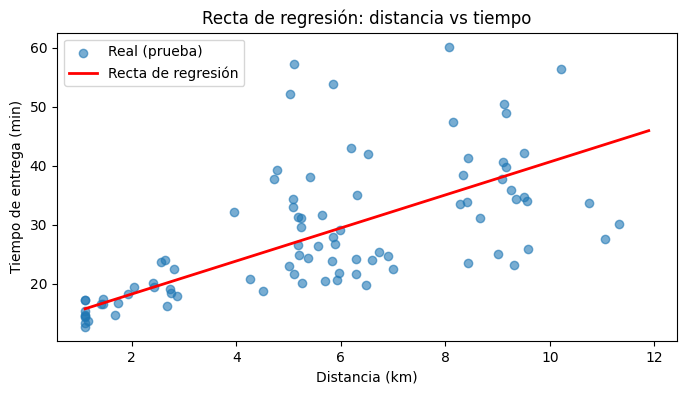

In [42]:
# GRÁFICO — LECTURA: puntos reales del conjunto de prueba y la recta estimada por el modelo.
# INTERPRETACIÓN: la recta sube con la distancia; la dispersión de los puntos alrededor de ella es el error
# que el modelo no logra explicar solo con la distancia.
x_linea = pd.DataFrame({"distancia_km": np.linspace(X["distancia_km"].min(), X["distancia_km"].max(), 100)})
plt.figure(figsize=(8, 4))
plt.scatter(X_test["distancia_km"], y_test, alpha=0.6, label="Real (prueba)")
plt.plot(x_linea["distancia_km"], modelo.predict(x_linea), color="red", linewidth=2, label="Recta de regresión")
plt.xlabel("Distancia (km)"); plt.ylabel("Tiempo de entrega (min)")
plt.title("Recta de regresión: distancia vs tiempo")
plt.legend(); plt.show()

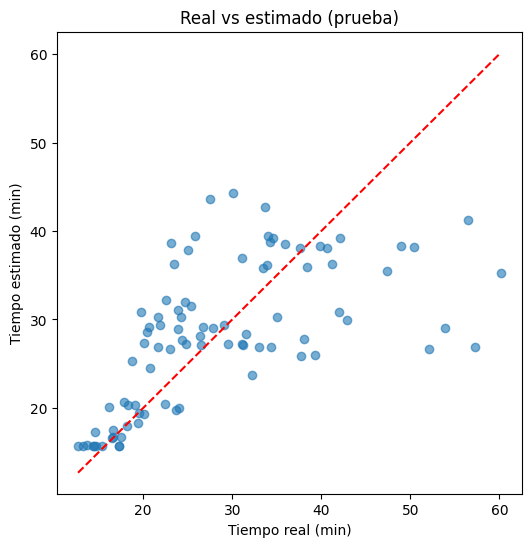

In [43]:
# GRÁFICO — LECTURA: tiempo real vs tiempo estimado en prueba. La línea roja es el ajuste perfecto (real = estimado).
# INTERPRETACIÓN: los puntos cerca de la línea son buenas estimaciones; los alejados son entregas que el
# modelo sub o sobreestima porque influyen otros factores (carga de la sede, ítems, tráfico).
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
lim = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lim, lim, "r--")
plt.xlabel("Tiempo real (min)"); plt.ylabel("Tiempo estimado (min)")
plt.title("Real vs estimado (prueba)")
plt.show()

In [44]:
# LECTURA: guardamos en SQLite la tabla predicciones_regresion con la distancia, el tiempo real,
# el estimado y el error de cada entrega de prueba; luego la comprobamos con SQL.
# RESULTADO: cantidad de filas guardadas y error absoluto promedio en minutos.
predicciones = pd.DataFrame({
    "distancia_km": X_test["distancia_km"].values,
    "tiempo_real_min": y_test.values,
    "tiempo_estimado_min": y_pred.round(2),
})
predicciones["error_min"] = (predicciones["tiempo_real_min"] - predicciones["tiempo_estimado_min"]).round(2)
predicciones.to_sql("predicciones_regresion", conn, if_exists="replace", index=False)
pd.read_sql('''SELECT COUNT(*) AS filas,
                      ROUND(AVG(ABS(error_min)), 2) AS error_abs_promedio_min
               FROM predicciones_regresion''', conn)

,filas,error_abs_promedio_min
0,89,6.26


**Pregunta 7.** El **coeficiente es 2.80**: por cada kilómetro adicional de distancia, el tiempo de entrega estimado aumenta en unos **2.8 minutos**. Por ejemplo, un pedido a 8 km se estima en 12.61 + 2.80 × 8 ≈ 35 min, y uno a 3 km en ≈ 21 min. El **intercepto es 12.61 minutos**: es el tiempo estimado para una distancia de 0 km, y se puede entender como el tiempo fijo de preparación y despacho del pedido antes de recorrer la distancia. Es razonable para el negocio, aunque en la base no hay entregas a menos de 1.11 km.

**Pregunta 8.** El **R² de prueba es 0.3842**: la distancia explica alrededor del 38 % de la variación del tiempo en entregas que el modelo no vio. El **RMSE es 8.76 minutos** (MSE 76.82): en promedio, la estimación se equivoca en unos 9 minutos, frente a un tiempo promedio de 28 minutos. El **R² de entrenamiento (0.5926) es mayor que el de prueba (0.3842)**: el modelo funciona peor con datos nuevos, lo que indica que la división de prueba (89 entregas) incluye casos más difíciles y que el resultado no es tan estable. Al ser un modelo de una sola variable no hay sobreajuste por complejidad, pero sí un límite claro. **Límites:** usa solo la distancia y deja fuera otros factores que también influyen (carga operativa de la sede, cantidad de ítems, tráfico, hora); supone una relación lineal; una correlación no prueba causalidad; y los datos son sintéticos de práctica.

## Actividad 5 — Conclusiones y recomendación

**Conclusión 1 — Integración y calidad.** Las cuatro tablas se integraron con LEFT JOIN sin perder ninguna de las 466 entregas y sin claves huérfanas. La base tenía problemas que distorsionaban el análisis (6 duplicados, 12 nulos, 20 fechas en otro formato, 22 textos con espacios y 12 tiempos extremos); tras la limpieza quedaron 441 entregas sin nulos ni duplicados, guardadas en `dataset_limpio`.

**Conclusión 2 — Regresión.** La distancia tiene una relación positiva con el tiempo de entrega: cada kilómetro suma unos 2.8 minutos sobre una base de 12.6 minutos. Sin embargo, el modelo explica el 38 % de la variación en prueba (R² = 0.3842) con un error típico de 8.76 minutos, y baja frente al 59 % de entrenamiento, por lo que sirve como referencia general, no como estimación precisa.

**Conclusión 3 — Siguiente paso del PMD1.** Como la carga operativa (correlación 0.85 con la distancia) y los ítems del pedido también se relacionan con el tiempo, el siguiente paso es probar un modelo con varias variables y, en la fase de K-Means, segmentar las entregas por distancia, carga y tiempo para identificar grupos de pedidos problemáticos.

**Recomendación para el jefe:** Recomendamos usar la distancia para dar al cliente un tiempo estimado de entrega: unos 13 minutos de preparación más casi 3 minutos por cada kilómetro (por ejemplo, unos 35 minutos para 8 km). Como la estimación puede fallar en unos 9 minutos y la distancia solo explica cerca del 38 % de las diferencias, conviene comunicar un rango (estimado ± 9 min) y no tomar decisiones de personal solo con este modelo hasta incluir la carga de cada sede.

**Pregunta 9.** La calidad de la base mejoró porque pasó de 466 registros con 12 nulos, 6 duplicados, fechas mezcladas y textos con espacios a 441 entregas sin nulos ni duplicados, con fechas en un solo formato y sin tiempos extremos; por eso la relación distancia-tiempo pasó de 0.7242 a 0.7433. El modelo puede apoyar la decisión de **prometer tiempos de entrega por distancia** (y, por ejemplo, definir un radio máximo de reparto o un recargo para pedidos lejanos), siempre comunicando un margen de unos 9 minutos.